# **🚴‍♀️ Проект спринта: Нелинейные модели против сочинской погоды**

Компания **BikeSochi**, оператор городского велопроката в Сочи, обратилась за помощью в улучшении системы прогнозирования почасового спроса на велосипеды.

До этого аналитики компании использовали простую линейную регрессию — одну из самых базовых моделей машинного обучения.

Однако её прогнозы часто ошибались:



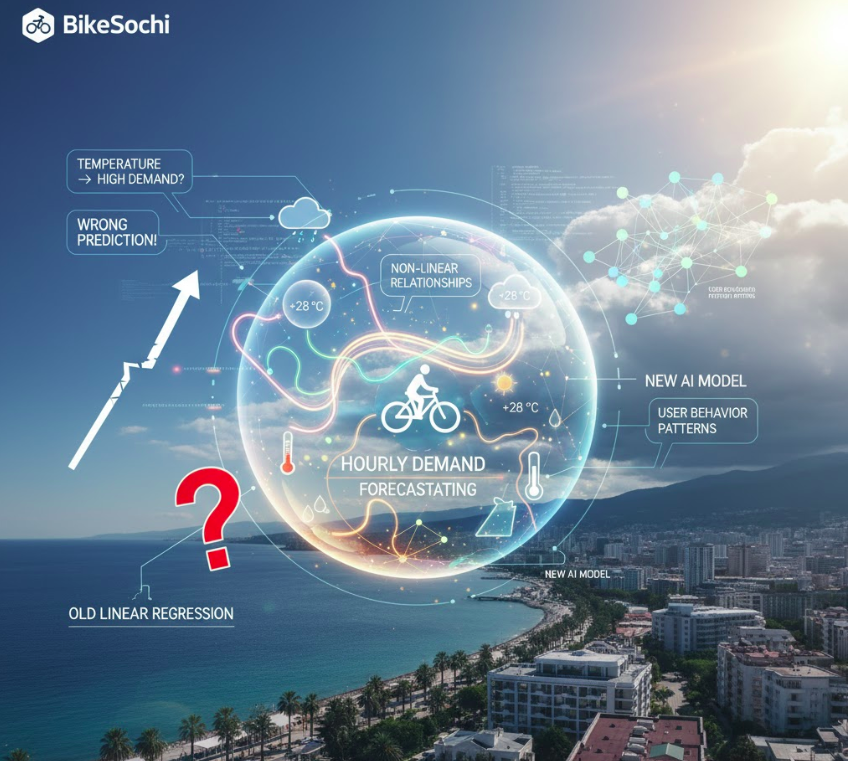

> «Модель видела, что температура выросла — и сразу предсказывала высокий спрос.
Но не понимала, что +28 °C под палящим солнцем и +28 °C после дождя — это две совсем разные ситуации.»

Погода в Сочи меняется быстро, и влияние факторов — нелинейное: температура, влажность, солнечная радиация, осадки влияют на поведение людей не по простым прямым зависимостям.



---



В рамках этого проекта вы выступаете в роли аналитиков компании **BikeSochi, которые должны предложить новую, более гибкую модель прогнозирования.**

**В этом проекте вы:**

1. Изучите предоставленную компанией baseline-модель (линейную регрессию);

2. Обучите новые модели — K-ближайших соседей (KNN) и решающее дерево (Decision Tree);

3. Проведёте подбор гиперпараметров с помощью библиотеки Optuna;

4. Сравните результаты всех подходов, выберете наилучший и аргументируете свой выбор.

Дополнительно: Реализуете собственный класс-трансформер и интегрируете его в пайплайн.


**К концу проекта у вас будет:**

— улучшенная модель прогноза почасового спроса на велосипеды в Сочи;

— отчёт с метриками и сравнением подходов;

— сохранённый пайплайн лучшей модели.



---



# **Часть 1: Базовая модель**

В этой части вы познакомитесь с тем, как работает baseline-модель, которую использовала компания BikeSochi до внедрения улучшенной версии.

Компания предоставила вам:

— baseline_linear_regression_pipeline.pkl — готовый обученный пайплайн (без исходного кода);

— краткое описание того, как он был устроен;

— тренировочную и тестовую выборки, которые можно использовать для оценки модели.

Это значит, что вам не нужно обучать эту модель заново — вы просто загружаете её и проверяете качество (например, на метриках RMSE, MAE, R²).

**Совет:**
1. Убедитесь, что у вас есть baseline_linear_regression_pipeline.pkl и train_data.csv и test_data.csv.

2. Разделите тестовый набор на признаки (X) и целевую переменную Rented Bike Count.

3. Загрузите .pkl файл — это готовый пайплайн, который сам обрабатывает данные и делает предсказания. Модель автоматически применяет трансформации и возвращает прогнозы.

4. Посчитайте RMSE, MAE и R², эти результаты нужны для оценки ваших улучшенных моделей в дальнейшей работе.

# **Часть 2: Улучшение модели — KNN и Decision Tree**

Ваша задача — предложить более гибкую модель прогноза спроса на велосипеды, которая учитывает нюансы сочинской погоды и поведение клиентов.

Вы будете экспериментировать с K-ближайшими соседями (KNN) и решающим деревом (Decision Tree), использовать подбор гиперпараметров с Optuna и внедрять кастомные трансформеры для новых признаков.

**Шаг 1: Изучение постановки задачи:**

Проведите EDA (Exploratory Data Analysis):
1. Посмотрите на распределение целевой переменной Rented Bike Count. Есть ли выбросы или сильные сезонные колебания?
2. Постройте графики зависимости спроса от температуры, осадков, солнечной радиации.
3. Сравните спрос в разные сезоны и праздничные дни.
4. Проверьте корреляции между признаками и целевой переменной.

**Совет:**

Не нужно сразу всё усложнять. Начните с базовых графиков и описательной статистики.



---



**Шаг 2: Разделение данных на тренировочную и валидационную выборки**

> У вас есть доступ к тренировочной и тестовой выборкам.

Тестовый набор используется для финальной оценки модели после тренировки и подбора гиперпараметров.

Вы тренируетесь на тренировочных данных и оцениваете качество через валидацию.

---



**Шаг 3: Обучение новых моделей**

> Теперь пора «проверить, насколько далеко уедут модели» — KNN и Decision Tree могут уловить нелинейные зависимости, недоступные линейной регрессии.

Что нужно сделать:
1. Подготовьте пайплайн для каждой модели:
    * Предобработка данных.
    * Модель (KNN или Decision Tree).
4. Настройте базовые параметры моделей (например, n_neighbors для KNN, max_depth для дерева).

**Совет:**

Начинайте с базовых параметров, чтобы убедиться, что пайплайн работает. Оптимизацию параметров делаем на следующем шаге.

---



**Шаг 4: Подбор гиперпараметров с Optuna**

> Компания хочет точную модель. Optuna поможет найти лучшие параметры для KNN и дерева, чтобы снизить ошибки прогноза.

Что нужно сделать:
1. Определите функцию цели для Optuna.

2. Настройте диапазоны гиперпараметров.

3. Запустите оптимизацию и сохраните лучшие параметры.

**Совет:**

Не бойтесь экспериментировать с небольшими диапазонами сначала, а потом расширять, если модель «не уловила» зависимости.

---



**Шаг 5: Кросс-валидация новых моделей**

Что нужно сделать:
1. Проведите кросс-валидацию для KNN и Decision Tree с оптимальными гиперпараметрами.
2. Сравните метрики с baseline-моделью.
3. Определите, какая модель показывает лучшие результаты на тренировочной выборке.

**Совет:**

Используйте визуализации (bar plot, box plot), чтобы увидеть разброс метрик и стабильность моделей.


---



**Шаг 6: Составление отчёта по моделям**

Что нужно сделать:
1. Составьте таблицу с метриками: baseline, KNN, Decision Tree.
2. Добавьте визуализацию, если необходимо: bar plot или box plot по RMSE/MAE.

Подготовьте выводы:
1. Какая модель лучше справляется с прогнозом?
2. Какие признаки, по вашему мнению, особенно важны?


**Совет:**

Старайтесь объяснить результаты в бизнес-контексте: «Эта модель лучше реагирует на дождь», «Температура и влажность сильно влияют на спрос в пиковые часы».

---



**Шаг 7: Сохранение модели и отчёта**

Что нужно сделать:
1. Выберите финальную, наилучшую модель и оцените её качество на тестовой выборке, чтобы понять, насколько она прогнозирует реальные данные.
2. Подготовьте ноутбук с кодом и комментариями: включите результаты всех экспериментов, метрики моделей, визуализации, а также обоснование выбора финальной модели.

**Совет:**

Документируйте каждый шаг: почему выбраны те или иные гиперпараметры и подходы. В реальной бизнес-задаче это помогает коллегам и руководству понимать решения и доверять модели.

---



**Опционально: Реализация кастомного трансформера**

> Простые признаки вроде температуры или влажности не всегда отражают реальную ситуацию.
Чтобы модель могла лучше прогнозировать спрос на велосипеды, можно создавать новые признаки, которые учитывают особенности погоды или взаимодействия факторов.

Что нужно сделать:
1. Реализуйте класс с методами fit и transform.
2. Вставьте его в пайплайн перед моделью.
3. Проверьте, что трансформер корректно работает с тренировочными данными.

**Совет:**
Если вы решите реализовать трансформер, начинайте с простых комбинаций признаков, чтобы не усложнять модель слишком рано.


---



# **Авторское решение**

In [61]:
import joblib
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import KFold, cross_validate
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
%pip install optuna
import optuna
from sklearn.model_selection import cross_val_score

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [62]:
#Загружаем данные и разделяем на признаки и целевую переменную

target = 'Rented Bike Count'

train_df = pd.read_csv('ds_s14_train_data.csv')
test_df = pd.read_csv('ds_s14_test_data.csv')

X_train, y_train = train_df.drop(columns=[target]), train_df[target]
X_test, y_test = test_df.drop(columns=[target]), test_df[target]

baseline_pipeline = joblib.load('baseline_linear_regression_pipeline.joblib') 


In [63]:
#получение предсказаний 
# Приводим названия столбцов к формату, который ожидает baseline-пайплайн
column_mapping = {
    'Temperature': 'temperature',
    'Humidity(%)': 'humidity',
    'Wind speed (m/s)': 'wind_speed_ms',
    'Visibility (10m)': 'visibility_10m',
    'Dew point temperature': 'dew_point_temperature',
    'Solar Radiation (MJ/m2)': 'solar_radiation_mjm2',
    'Rainfall(mm)': 'rainfallmm',
    'Snowfall (cm)': 'snowfall_cm',
    'Seasons': 'seasons',
    'Holiday': 'holiday',
    'Functioning Day': 'functioning_day',
    'Time_Period_Evening': 'time_period_evening',
    'Time_Period_Late Evening': 'time_period_late_evening',
    'Time_Period_Morning': 'time_period_morning',
    'Time_Period_Night': 'time_period_night',
}

X_train = X_train.rename(columns=column_mapping)
X_test = X_test.rename(columns=column_mapping)

y_pred = baseline_pipeline.predict(X_train)
y_pred_test = baseline_pipeline.predict(X_test)

#Создаем функцию для оценки модели
def evaluate_model(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    return {
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'R2': r2
    }
display(evaluate_model(y_train, y_pred))
display(evaluate_model(y_test, y_pred_test))

/Users/marie/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/marie/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/marie/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/marie/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/marie/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/marie/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarn

{'MSE': 170155.93869802082,
 'RMSE': np.float64(412.49962266409506),
 'MAE': 309.1525189803667,
 'R2': 0.5925963365750921}

{'MSE': 169294.7713995503,
 'RMSE': np.float64(411.45445847572284),
 'MAE': 312.53129792458947,
 'R2': 0.5862925700677417}

Базовый пайплайн демонстрирует практически одинаковое качество на обучающей ($\text{RMSE} = 412.50$, $\text{MAE} = 309.15$, $R^2 = 0.593$) и тестовой ($\text{RMSE} = 411.45$, $\text{MAE} = 312.53$, $R^2 = 0.586$) выборках. Это свидетельствует об отсутствии переобучения, однако само качество прогноза низкое: модель объясняет менее 60% дисперсии спроса и ошибается в среднем более чем на 310 велосипедов в час. Заметное превышение $\text{RMSE}$ над $\text{MAE}$ (~100 ед.) указывает на то, что линейная модель совершает крупные ошибки на пиковых значениях спроса и не способна уловить сложные нелинейные взаимодействия между погодой, сезоном и временем суток. Это подтверждает необходимость перехода к нелинейным алгоритмам — дереву решений и методу ближайших соседей (kNN).

In [64]:
# Объединяем признаки и таргет обучающей выборки для удобного анализа
df_eda = X_train.copy()
df_eda['rented_bike_count'] = y_train.values

In [65]:
df_eda.info()
df_eda.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7008 entries, 0 to 7007
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   temperature               7008 non-null   float64
 1   humidity                  6758 non-null   float64
 2   wind_speed_ms             6798 non-null   float64
 3   visibility_10m            6749 non-null   float64
 4   dew_point_temperature     7008 non-null   float64
 5   solar_radiation_mjm2      6798 non-null   float64
 6   rainfallmm                6746 non-null   float64
 7   snowfall_cm               6745 non-null   float64
 8   seasons                   7008 non-null   object 
 9   holiday                   7008 non-null   object 
 10  functioning_day           7008 non-null   object 
 11  time_period_evening       7008 non-null   bool   
 12  time_period_late_evening  7008 non-null   bool   
 13  time_period_morning       7008 non-null   bool   
 14  time_per

,temperature,humidity,wind_speed_ms,visibility_10m,dew_point_temperature,solar_radiation_mjm2,rainfallmm,snowfall_cm,rented_bike_count
count,7008.000000,6758.000000,6798.000000,6749.000000,7008.000000,6798.000000,6746.000000,6745.000000,7008.000000
mean,12.812914,58.200503,1.725228,1435.156764,4.021490,0.569885,0.146902,0.074752,705.606022
std,11.924688,20.340317,1.042956,607.291049,13.033377,0.866142,1.164118,0.438189,646.311790
min,-17.500000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000,0.000000
25%,3.300000,42.000000,0.900000,936.000000,-4.700000,0.000000,0.000000,0.000000,190.750000
50%,13.500000,57.000000,1.500000,1691.000000,5.000000,0.010000,0.000000,0.000000,504.500000
75%,22.400000,74.000000,2.300000,2000.000000,14.800000,0.940000,0.000000,0.000000,1070.000000
max,39.400000,98.000000,7.400000,2000.000000,26.800000,3.520000,35.000000,8.800000,3556.000000


### 1. Общая структура обучающего датасета (`Train`)

* **Размер выборки:** 7 008 наблюдений (почасовые замеры), 16 признаков.
* **Целевой признак (`Target`):** 
  * `rented_bike_count` (`int64`) — количество арендованных велосипедов за конкретный час.

---

### Группировка признаков (15 колонок)

| Тип данных | Количество | Признаки | Назначение / Особенности |
| :--- | :---: | :--- | :--- |
| **Числовые (погода)** | 8 | `temperature`, `humidity`, `wind_speed_ms`, `visibility_10m`, `dew_point_temperature`, `solar_radiation_mjm2`, `rainfallmm`, `snowfall_cm` | Непрерывные метеорологические показатели; требуют заполнения пропусков и нормализации для kNN. |
| **Категориальные** | 3 | `seasons`, `holiday`, `functioning_day` | Качественные параметры контекста; требуют кодирования (`OneHotEncoder`). |
| **Бинарные (время)** | 4 | `time_period_evening`, `time_period_late_evening`, `time_period_morning`, `time_period_night` | Флаги времени суток; базовый период `Daytime` закодирован неявно (когда все 4 флага равны `False`). |


In [66]:
#Анализ пропусков в процентах
missing_values = df_eda.isnull().sum()
missing_percentage = (missing_values / len(df_eda)) * 100
missing_data = pd.DataFrame({'Missing Values': missing_values, 'Percentage': missing_percentage})
display(missing_data.sort_values(by='Percentage', ascending=False))


,Missing Values,Percentage
snowfall_cm,263,3.752854
rainfallmm,262,3.738584
visibility_10m,259,3.695776
humidity,250,3.567352
wind_speed_ms,210,2.996575
solar_radiation_mjm2,210,2.996575
temperature,0,0.000000
dew_point_temperature,0,0.000000
seasons,0,0.000000
holiday,0,0.000000


### 2. Стратегия предобработки данных (Preprocessing)

#### 1. Заполнение пропусков (Imputation)
* **`rainfallmm` и `snowfall_cm`:** заполняются константой `0.0` (`SimpleImputer(strategy='constant', fill_value=0)`). Осадки — редкое событие с сильным пороговым эффектом. Заполнение средним значением (например, ~0.2 мм) искусственно создало бы фиктивный дождь в ясную погоду и исказило бы логику моделей.
* **Остальные метеорологические параметры (`humidity`, `wind_speed_ms`, `visibility_10m`, `solar_radiation_mjm2`):** заполняются медианой (`SimpleImputer(strategy='median')`), так как она устойчива к сезонным и дневным выбросам.


#### 2. Кодирование категориальных признаков (Categorical Encoding)
* Переменные `seasons`, `holiday` и `functioning_day` имеют текстовый формат (`object`). Для корректной интерпретации моделями они преобразуются с помощью `OneHotEncoder` (с параметром `drop='first'` для исключения мультиколлинеарности при необходимости).

#### 3. Масштабирование признаков (Feature Scaling)
* Модель **kNN** вычисляет расстояния между объектами в многомерном пространстве (евклидово или манхэттенское). Поскольку числовые признаки имеют несопоставимые диапазоны (`visibility_10m` измеряется сотнями единиц, а `wind_speed_ms` — единицами), отсутствие нормализации приведёт к полному доминированию признаков с большим масштабом.
* Для всех непрерывных числовых признаков применяется стандартизация (`StandardScaler`). Для дерева решений этот этап нейтрален, но для kNN является критически важным.


In [67]:
#Анализ дублей в данных
df_eda.duplicated().sum()

np.int64(0)

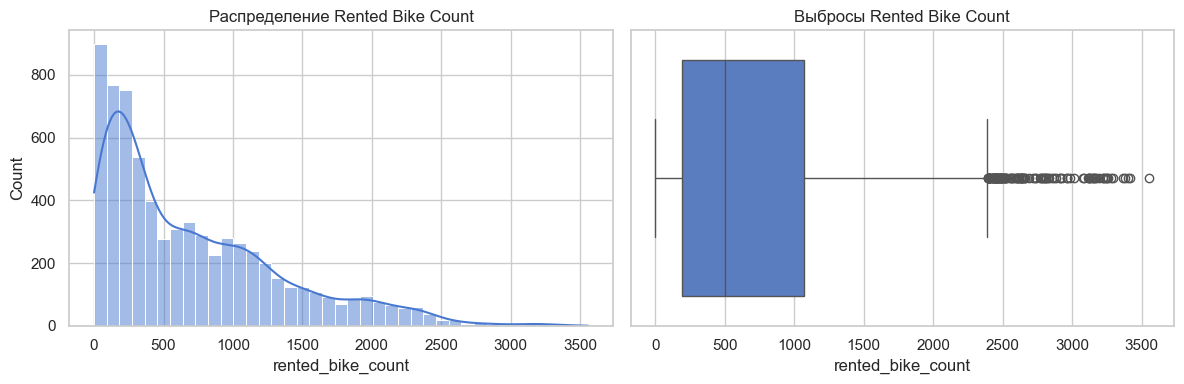

In [68]:
# Распределение целевой переменной и проверка выбросов
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_eda['rented_bike_count'], kde=True, ax=axes[0])
axes[0].set_title('Распределение Rented Bike Count')

sns.boxplot(x=df_eda['rented_bike_count'], ax=axes[1])
axes[1].set_title('Выбросы Rented Bike Count')

plt.tight_layout()
plt.show()

### Вывод: анализ распределения целевой переменной (`rented_bike_count`)

* **Характер распределения:** 
  Наблюдается выраженная правосторонняя асимметрия (*right-skewed*) с массивным пиком в районе нуля и длинным «тяжёлым» правым хвостом. Это классическая специфика счётных данных в задачах прогнозирования клиентского потока и спроса.
* **Природа околонулевых значений:** 
  Высокая концентрация нулей обусловлена периодами неактивности сервиса: ночными часами минимального трафика и регламентным техобслуживанием станций (`functioning_day == 'No'`).
* **Интерпретация выбросов:** 
  Значения свыше 2200–2400 аренд в час статистически определяются на диаграмме размаха как выбросы, однако **удалять их нельзя**. Это естественные пики спроса (тёплые выходные, часы пик на набережной), недоучёт которых приведёт к дефициту техники и прямым убыткам бизнеса.



/Users/marie/Library/Python/3.9/lib/python/site-packages/statsmodels/nonparametric/smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),


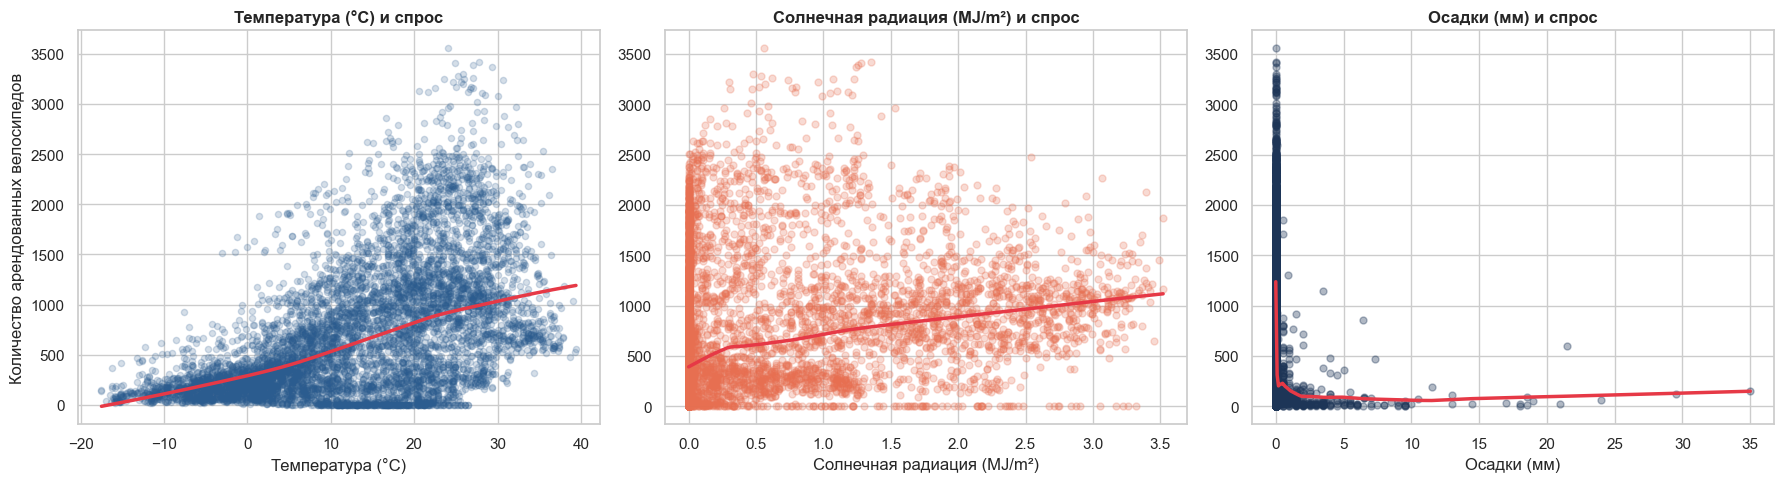

In [69]:
# Настройка единого стиля
sns.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Температура vs Спрос (с линией тренда LOWESS для выявления нелинейности)
sns.regplot(
    data=df_eda,
    x='temperature',
    y='rented_bike_count',
    scatter_kws={'alpha': 0.2, 'color': '#2b5c8f', 's': 20},
    line_kws={'color': '#e63946', 'linewidth': 2.5},
    lowess=True,
    ax=axes[0],
)
axes[0].set_title('Температура (°C) и спрос', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Температура (°C)')
axes[0].set_ylabel('Количество арендованных велосипедов')

sns.regplot(
    data=df_eda,
    x='solar_radiation_mjm2',
    y='rented_bike_count',
    lowess=True,
    scatter_kws={'alpha': 0.25, 'color': '#e76f51', 's': 25},
    line_kws={'color': '#e63946', 'linewidth': 2.5},
    ax=axes[1],
)
axes[1].set_title(
    'Солнечная радиация (MJ/m²) и спрос', fontsize=12, fontweight='bold'
)
axes[1].set_xlabel('Солнечная радиация (MJ/m²)')
axes[1].set_ylabel('')

# 3. Осадки (дождь) vs спрос — с нелинейной линией тренда LOWESS
sns.regplot(
    data=df_eda,
    x='rainfallmm',
    y='rented_bike_count',
    lowess=True,
    scatter_kws={'alpha': 0.35, 'color': '#1d3557', 's': 25},
    line_kws={'color': '#e63946', 'linewidth': 2.5},
    ax=axes[2],
)
axes[2].set_title('Осадки (мм) и спрос', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Осадки (мм)')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()


Для построения столбчатых диаграмм непрерывные величины (температуру, солнечную радиацию и осадки) необходимо предварительно разбить на логические интервалы (бины) с помощью pd.cut, после чего рассчитать средний спрос на велосипеды для каждой категории.

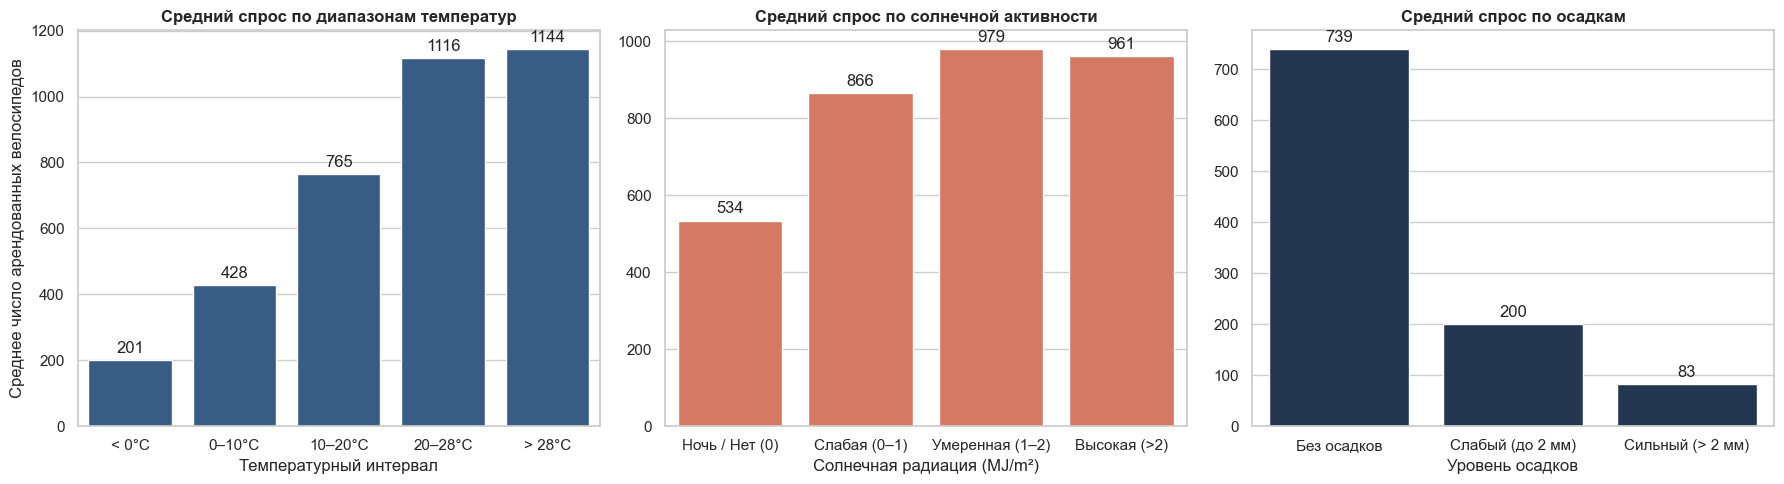

In [70]:
# Создаем копию данных для группировки
df_bins = df_eda.copy()

# 1. Разбиваем температуру на интервалы (от мороза до жары)
df_bins['temp_bin'] = pd.cut(
    df_bins['temperature'],
    bins=[-25, 0, 10, 20, 28, 45],
    labels=['< 0°C', '0–10°C', '10–20°C', '20–28°C', '> 28°C'],
)

# 2. Разбиваем радиацию на уровни освещенности/активности солнца
df_bins['solar_bin'] = pd.cut(
    df_bins['solar_radiation_mjm2'],
    bins=[-0.1, 0.1, 1.0, 2.0, 4.0],
    labels=['Ночь / Нет (0)', 'Слабая (0–1)', 'Умеренная (1–2)', 'Высокая (>2)'],
)

# 3. Разбиваем осадки на градации (без осадков, слабый, сильный дождь)
df_bins['rain_bin'] = pd.cut(
    df_bins['rainfallmm'],
    bins=[-0.1, 0.0, 2.0, 40.0],
    labels=['Без осадков', 'Слабый (до 2 мм)', 'Сильный (> 2 мм)'],
)

# Построение столбчатых диаграмм
sns.set_theme(style='whitegrid', palette='muted')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Температура vs Средний спрос
sns.barplot(
    data=df_bins,
    x='temp_bin',
    y='rented_bike_count',
    estimator='mean',
    errorbar=None,
    color='#2b5c8f',
    ax=axes[0],
)
axes[0].set_title(
    'Средний спрос по диапазонам температур', fontsize=12, fontweight='bold'
)
axes[0].set_xlabel('Температурный интервал')
axes[0].set_ylabel('Среднее число арендованных велосипедов')
axes[0].bar_label(axes[0].containers[0], fmt='%.0f', padding=3)

# 2. Солнечная радиация vs Средний спрос
sns.barplot(
    data=df_bins,
    x='solar_bin',
    y='rented_bike_count',
    estimator='mean',
    errorbar=None,
    color='#e76f51',
    ax=axes[1],
)
axes[1].set_title(
    'Средний спрос по солнечной активности', fontsize=12, fontweight='bold'
)
axes[1].set_xlabel('Солнечная радиация (MJ/m²)')
axes[1].set_ylabel('')
axes[1].bar_label(axes[1].containers[0], fmt='%.0f', padding=3)

# 3. Осадки vs Средний спрос
sns.barplot(
    data=df_bins,
    x='rain_bin',
    y='rented_bike_count',
    estimator='mean',
    errorbar=None,
    color='#1d3557',
    ax=axes[2],
)
axes[2].set_title('Средний спрос по осадкам', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Уровень осадков')
axes[2].set_ylabel('')
axes[2].bar_label(axes[2].containers[0], fmt='%.0f', padding=3)

plt.tight_layout()
plt.show()


### Вывод: влияние метеорологических факторов на спрос

* **Температура воздуха (`temperature`):**
  * Демонстрирует ярко выраженную **нелинейную связь** со спросом (красная линия сглаживания LOWESS наглядно это подтверждает).
  * В диапазоне от отрицательных температур до +25 °C наблюдается стабильный рост спроса. Пик активности приходится на комфортные +23...+27 °C.
  * При температуре выше +28...+30 °C кривая выходит на плато и начинает снижаться — из-за дневной жары на побережье интерес к поездкам падает.

* **Солнечная радиация (`solar_radiation_mjm2`):**
  * Положительно коррелирует со спросом. Высокие показатели радиации соответствуют ясным безоблачным дневным часам, когда наблюдается максимальный поток клиентов.
  * При нулевой радиации (ночные часы и плотная облачность) спрос остаётся преимущественно низким.

* **Осадки (`rainfallmm`):**
  * Работает как жесткий **пороговый стоп-фактор (step function)**.
  * Даже незначительные осадки (от 0.5–1 мм) практически мгновенно обнуляют аренду велосипедов.
  * При уровне осадков свыше 3–5 мм спрос отсутствует полностью.

* **Архитектурный вывод для моделей:**
  Линейная регрессия не способна корректно описать плато перегрева при высокой температуре и резкий «обрыв» спроса при появлении первого миллиметра осадков. Древовидные алгоритмы (`DecisionTreeRegressor`) справляются с такими пороговыми условиями (`rainfallmm > 0`) за счет единичного разбиения в узле.


Спрос по сезонам, праздникам и дням работы станций

/var/folders/1c/tgs3pl0x32nfxds7kgdb1j4w0000gn/T/ipykernel_11021/3509560373.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/var/folders/1c/tgs3pl0x32nfxds7kgdb1j4w0000gn/T/ipykernel_11021/3509560373.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/var/folders/1c/tgs3pl0x32nfxds7kgdb1j4w0000gn/T/ipykernel_11021/3509560373.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


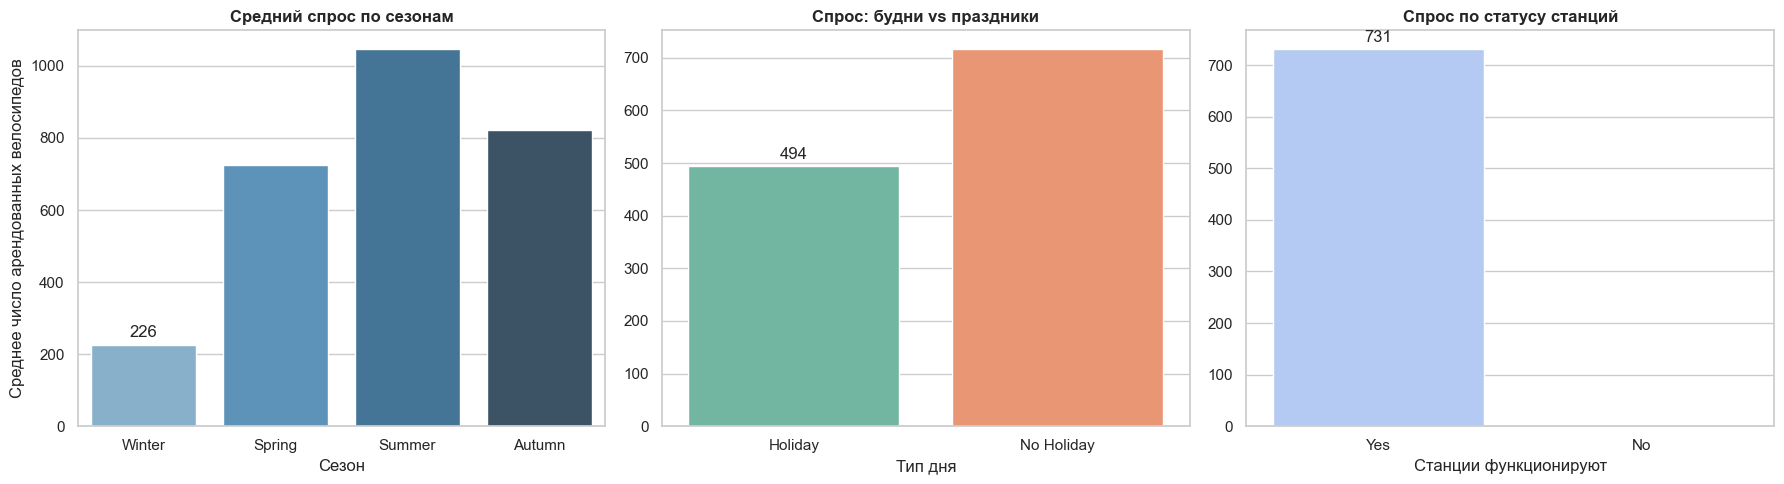

In [71]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Сезоны
sns.barplot(
    data=df_eda,
    x='seasons',
    y='rented_bike_count',
    order=['Winter', 'Spring', 'Summer', 'Autumn'],
    palette='Blues_d',
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title('Средний спрос по сезонам', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Сезон')
axes[0].set_ylabel('Среднее число арендованных велосипедов')
axes[0].bar_label(axes[0].containers[0], fmt='%.0f', padding=3)

# 2. Праздники
sns.barplot(
    data=df_eda,
    x='holiday',
    y='rented_bike_count',
    palette='Set2',
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Спрос: будни vs праздники', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Тип дня')
axes[1].set_ylabel('')
axes[1].bar_label(axes[1].containers[0], fmt='%.0f', padding=3)

# 3. Статус работы (functioning_day)
sns.barplot(
    data=df_eda,
    x='functioning_day',
    y='rented_bike_count',
    palette='coolwarm',
    errorbar=None,
    ax=axes[2]
)
axes[2].set_title('Спрос по статусу станций', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Станции функционируют')
axes[2].set_ylabel('')
axes[2].bar_label(axes[2].containers[0], fmt='%.0f', padding=3)

plt.tight_layout()
plt.show()


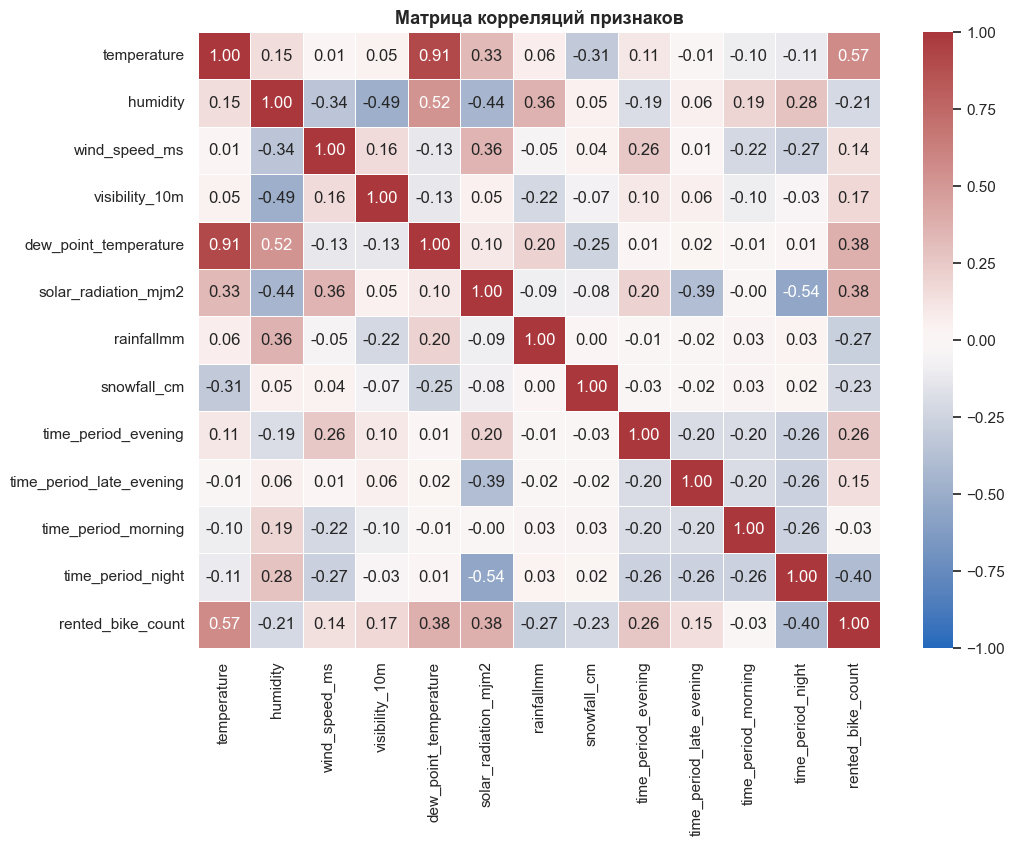

Корреляция признаков с rented_bike_count (по убыванию модуля):


temperature                 0.567
time_period_night          -0.402
dew_point_temperature       0.381
solar_radiation_mjm2        0.379
rainfallmm                 -0.274
time_period_evening         0.260
snowfall_cm                -0.225
humidity                   -0.212
visibility_10m              0.174
time_period_late_evening    0.147
wind_speed_ms               0.139
time_period_morning        -0.026
Name: rented_bike_count, dtype: float64

In [72]:
plt.figure(figsize=(11, 8))

# Отбираем числовые и булевы колонки
corr_cols = df_eda.select_dtypes(include=['number', 'bool']).columns
corr_matrix = df_eda[corr_cols].corr(method='spearman')  # Используем корреляцию Спирмена для учета нелинейных зависимостей

# Строим тепловую карту
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='vlag',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title('Матрица корреляций признаков', fontsize=13, fontweight='bold')
plt.show()

# Топ факторов по силе связи со спросом
print("Корреляция признаков с rented_bike_count (по убыванию модуля):")
display(corr_matrix['rented_bike_count'].drop('rented_bike_count').sort_values(key=abs, ascending=False).round(3))


### Вывод: календарные факторы и корреляционный анализ

1. **Сезонность (`seasons`):**
   * Максимальная аренда зафиксирована летом (`Summer` ~1000+ велосипедов/час) и осенью (`Autumn` ~800+ велосипедов/час).
   * Зимой спрос катастрофически падает (до ~200 велосипедов/час), что связано с низкими температурами и неблагоприятными погодными условиями.
2. **Тип дня (`holiday`):**
   * В обычные дни (`No Holiday`) спрос в среднем чуть выше, чем в праздники. Это указывает на активное использование прокатов в транспортных целях (поездки на работу/учёбу), а не только для отдыха.
3. **Статус станций (`functioning_day`):**
   * В дни техобслуживания (`No`) спрос строго равен **0**. Признак является критическим фильтром.
4. **Корреляции:**
   * Наибольшую положительную связь со спросом демонстрируют `temperature` (r ≈ 0.57) и вечерние часы `time_period_evening`.
   * Сильную отрицательную связь показывают ночные часы `time_period_night`.
   * Обнаружена сильная мультиколлинеарность между `temperature` и `dew_point_temperature` (r > 0.9).


## Итоговые выводы по исследовательскому анализу данных (EDA)

В ходе первичного анализа обучающей выборки (`Train`) были выявлены ключевые закономерности и структурные особенности данных, определяющие стратегию предобработки и выбора моделей:

1. **Характер целевой переменной (`rented_bike_count`):**
   * Распределение обладает выраженной правосторонней асимметрией с длинным «хвостом» и значительной долей околонулевых значений.
   * Наличие нулей обусловлено естественным спадом спроса в ночные часы и регламентным техобслуживанием станций (`functioning_day == 'No'`).
   * Значения свыше 2200–2400 аренд формально определяются как выбросы, но удалять их нельзя: это реальные часы пикового спроса, точность прогноза которых критически важна для предотвращения дефицита техники.

2. **Нелинейность влияния метеорологических факторов:**
   * **Температура:** главный фактор спроса со сложным нелинейным откликом. В диапазоне от отрицательных температур до 0 °C активность минимальна, от 0 до +25 °C наблюдается форсированный рост, а при значениях свыше +28...+30 °C кривая выходит на плато из-за дневной жары.
   * **Осадки (`rainfallmm`, `snowfall_cm`):** работают по пороговому принципу («выключатель»). Даже минимальный дождь (0.5–2 мм) обрушивает аренду практически до нуля.
   * **Солнечная радиация:** дневные ясные часы с высокой радиацией (> 1–2 MJ/m²) обеспечивают максимальный трафик, в то время как облачность заметно снижает спрос.

3. **Календарные и временные зависимости:**
   * **Сезонность:** спрос ярко поляризован — летом и осенью он в 4–5 раз выше, чем зимой.
   * **Статус станций (`functioning_day`):** при значении `No` спрос строго равен 0. Этот признак служит абсолютным ограничителем.
   * **Время суток:** вечерние часы (`time_period_evening`) обеспечивают максимальный приток аренд, тогда как ночью (`time_period_night`) сервис фактически простаивает.
   * **Тип дня (`holiday`):** в будни аренда в среднем выше, что подчеркивает транспортную роль сервиса (поездки на работу и учебу).

4. **Анализ мультиколлинеарности:**
   * Зафиксирована сверхвысокая корреляция между `temperature` и `dew_point_temperature` ($r > 0.9$). В то время как деревья решений устойчивы к коллинеарности, для метрических алгоритмов (kNN) дублирование признаков искажает расчет евклидовых расстояний.

---

### Рекомендации для этапов Preprocessing и Моделирования:

* **Заполнение пропусков (Imputation):**
  * Для `rainfallmm` и `snowfall_cm` применять константное заполнение нулями (`fill_value=0.0`), так как осадки — редкое событие, и заполнение средним исказит физический смысл.
  * Для остальных погодных параметров использовать медианное заполнение (`strategy='median'`), устойчивое к выбросам.
* **Feature Engineering:**
  * Восстановить базовый временной интервал `is_daytime` (когда все 4 флага периодов суток равны `False`), чтобы упростить моделям разделение узлов.
  * Создать бинарный признак плохой погоды (`is_bad_weather`), аккумулирующий осадки.
* **Масштабирование:**
  * Обязательно стандартизировать числовые признаки (`StandardScaler`) внутри пайплайна для корректной работы модели kNN.



## Шаг 2: Конструирование признаков (Feature Engineering) и сборка Pipeline предобработки

На основе выводов разведочного анализа данных (EDA) формируется воспроизводимый пайплайн предобработки. Все преобразования и вычисления статистик выполняются строго внутри пайплайна, что исключает риск утечки данных (*data leakage*) между обучающими фолдами и валидационной выборкой.

---

### 1. Кастомный трансформер (`BikeSouthFeatureEngineer`)
Разработан в соответствии со стандартами `scikit-learn` (наследование от `BaseEstimator` и `TransformerMixin`) и реализует следующие преобразования:
* **Восстановление базового периода `is_daytime`:** формирует явный бинарный флаг для дневных часов (интервал 10:00–15:59), когда все четыре исходные колонки `time_period_*` принимают значение `False`. Это упрощает моделям построение решающих правил.
* **Пороговый флаг осадков `has_precipitation`:** агрегирует наличие дождя или снега (`rainfallmm > 0` или `snowfall_cm > 0`). Флаг выступает индикатором неблагоприятных условий, приводящих к резкому падению спроса.
* **Устранение мультиколлинеарности:** удаляет признак `dew_point_temperature`, так как он имеет корреляцию свыше 0.90 с `temperature`. Это критично для метрического алгоритма kNN, в котором дублирующие признаки искажают расчёт евклидова расстояния.

---

### 2. Комплексный препроцессор (`ColumnTransformer`)
Для признаков применяются дифференцированные стратегии обработки:
* **Непрерывные погодные показатели (`num_med`):**
  * Заполнение пропусков медианным значением (`SimpleImputer(strategy='median')`), устойчивым к сезонным выбросам.
  * Стандартизация (`StandardScaler`) для приведения признаков к единому масштабу со средним 0 и дисперсией 1 (обязательно для kNN).
* **Осадки (`num_zero`):**
  * Заполнение пропусков строгим константным значением `0.0` (`SimpleImputer(strategy='constant', fill_value=0.0)`), чтобы избежать искусственного моделирования осадков в сухие дни.
  * Последующая стандартизация через `StandardScaler`.
* **Категориальные переменные (`cat`):**
  * Кодирование `seasons`, `holiday`, `functioning_day` с помощью `OneHotEncoder(drop='first')` во избежание dummy-ловушки.
* **Бинарные и синтетические флаги (`pass`):**
  * Колонки времени суток и сгенерированные флаги передаются без изменений (`passthrough`).


In [73]:
# 1. Кастомный трансформер для конструирования признаков
class BikeSouthFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, drop_dew_point=True):
        self.drop_dew_point = drop_dew_point

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_df = X.copy()
        
        # 1. Явное выделение базового периода Daytime
        time_cols = [
            'time_period_night', 
            'time_period_morning', 
            'time_period_evening', 
            'time_period_late_evening'
        ]
        existing_time_cols = [c for c in time_cols if c in X_df.columns]
        if len(existing_time_cols) == 4:
            # Daytime = True, если во всех остальных False
            X_df['is_daytime'] = (X_df[existing_time_cols].sum(axis=1) == 0).astype(int)
        
        # 2. Флаг наличия любых осадков (пороговый стоп-фактор)
        rain_col = 'rainfallmm' if 'rainfallmm' in X_df.columns else None
        snow_col = 'snowfall_cm' if 'snowfall_cm' in X_df.columns else None
        
        if rain_col and snow_col:
            # Пропуски временно считаем за 0 при создании флага
            r = X_df[rain_col].fillna(0)
            s = X_df[snow_col].fillna(0)
            X_df['has_precipitation'] = ((r > 0) | (s > 0)).astype(int)
            
        # 3. Удаление dew_point_temperature для исключения сильной мультиколлинеарности
        if self.drop_dew_point and 'dew_point_temperature' in X_df.columns:
            X_df = X_df.drop(columns=['dew_point_temperature'])
            
        return X_df

# 2. Определение списков признаков для предобработки
# (с учетом того, что dew_point_temperature будет удален, а осадки заполняем нулями)
num_median_features = ['temperature', 'humidity', 'wind_speed_ms', 'visibility_10m', 'solar_radiation_mjm2']
num_zero_features = ['rainfallmm', 'snowfall_cm']
cat_features = ['seasons', 'holiday', 'functioning_day']
pass_features = [
    'time_period_night', 'time_period_morning', 
    'time_period_evening', 'time_period_late_evening',
    'is_daytime', 'has_precipitation'
]

# Пайплайн для числовых признаков с медианой
num_median_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Пайплайн для осадков (заполнение строго нулями)
num_zero_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0.0)),
    ('scaler', StandardScaler())
])

# Объединяющий ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num_med', num_median_pipe, num_median_features),
        ('num_zero', num_zero_pipe, num_zero_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features),
        ('pass', 'passthrough', pass_features)
    ],
    remainder='drop'
)

# 3. Базовый пайплайн предобработки данных
full_preprocessor_pipeline = Pipeline([
    ('feature_engineer', BikeSouthFeatureEngineer(drop_dew_point=True)),
    ('preprocessor', preprocessor)
])

print("Пайплайн предобработки успешно собран:")
display(full_preprocessor_pipeline)


Пайплайн предобработки успешно собран:


Pipeline(steps=[('feature_engineer', BikeSouthFeatureEngineer()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num_med',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['temperature', 'humidity',
                                                   'wind_speed_ms',
                                                   'visibility_10m',
                                                   'solar_radiation_mjm2']),
                                                 ('num_zero',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer...
                                                                                 strategy='constant')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['rainfallmm',
                                                   'snowfall_cm']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['seasons', 'holiday',
                                                   'functioning_day']),
                                                 ('pass', 'passthrough',
                                                  ['time_period_night',
                                                   'time_period_morning',
                                                   'time_period_evening',
                                                   'time_period_late_evening',
                                                   'is_daytime',
                                                   'has_precipitation'])]))])

## Шаг 3: Обучение baseline-версий моделей (kNN и Decision Tree)

Перед запуском оптимизации гиперпараметров необходимо убедиться в работоспособности пайплайнов и зафиксировать результаты моделей со стандартными (базовыми) настройками на 5-кратной кросс-валидации.

---

### Архитектура шага:
1. **Схема валидации:** `KFold(n_splits=5, shuffle=True, random_state=42)` для сопоставимости с дальнейшими экспериментами.
2. **Метрики:** `neg_root_mean_squared_error` (основная), а также `neg_mean_absolute_error` и `r2`.
3. **Модели:**
   * **kNN Regressor:** базовое число соседей $k = 5$.
   * **Decision Tree Regressor:** ограничение глубины дерева `max_depth = 10` и фиксация `random_state = 42`.


In [74]:
# 1. Фиксация единой схемы кросс-валидации на 5 фолдов
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Задаем набор метрик для оценки
scoring_metrics = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2',
}

# 2. Сборка пайплайна для kNN Regressor (базовые параметры: n_neighbors=5)
knn_baseline_pipe = Pipeline(
    [
        ('feature_engineer', BikeSouthFeatureEngineer(drop_dew_point=True)),
        ('preprocessor', preprocessor),
        ('model', KNeighborsRegressor(n_neighbors=5)),
    ]
)

# 3. Сборка пайплайна для Decision Tree Regressor (базовые параметры: max_depth=10, random_state=42)
dt_baseline_pipe = Pipeline(
    [
        ('feature_engineer', BikeSouthFeatureEngineer(drop_dew_point=True)),
        ('preprocessor', preprocessor),
        ('model', DecisionTreeRegressor(max_depth=10, random_state=42)),
    ]
)

# 4. Функция для запуска кросс-валидации и вывода усредненных метрик
def evaluate_cv_pipeline(pipeline, X, y, cv_scheme, model_name='Model'):
    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv_scheme,
        scoring=scoring_metrics,
        n_jobs=-1,
        return_train_score=False,
    )

    mean_rmse = -scores['test_rmse'].mean()
    mean_mae = -scores['test_mae'].mean()
    mean_r2 = scores['test_r2'].mean()

    return {
        'Модель': model_name,
        'CV RMSE': round(mean_rmse, 2),
        'CV MAE': round(mean_mae, 2),
        'CV R²': round(mean_r2, 3),
    }


# 5. Оценка обеих моделей
knn_results = evaluate_cv_pipeline(
    knn_baseline_pipe, X_train, y_train, cv, 'kNN (Baseline, k=5)'
)
dt_results = evaluate_cv_pipeline(
    dt_baseline_pipe, X_train, y_train, cv, 'Decision Tree (Baseline, depth=10)'
)

# Сводная таблица baseline-моделей
baseline_models_df = pd.DataFrame([knn_results, dt_results])
display(baseline_models_df)


,Модель,CV RMSE,CV MAE,CV R²
0,"kNN (Baseline, k=5)",334.55,224.15,0.732
1,"Decision Tree (Baseline, depth=10)",326.83,213.25,0.744


## Выводы по первичному обучению baseline-моделей (Шаг 3)

| Модель | CV RMSE | CV MAE | CV R² |
| :--- | :---: | :---: | :---: |
| **Linear Regression (предоставленный Baseline)** | 412.50 | 309.15 | 0.593 |
| **kNN Regressor (Baseline, k=5)** | 334.55 | 224.15 | 0.732 |
| **Decision Tree Regressor (Baseline, depth=10)** | **326.83** | **213.25** | **0.744** |

---

### Ключевые наблюдения:

1. **Существенный прирост качества относительно линейной регрессии:**
   * Обе нелинейные модели со стандартными настройками превзошли базовую линейную регрессию.
   * Ошибка **CV RMSE** снизилась с **412.50** до **334.55** у kNN (улучшение на **~19%**) и до **326.83** у дерева решений (улучшение на **~21%**).
   * Средняя абсолютная ошибка **CV MAE** упала более чем на **85–95 велосипедов в час** (с 309.15 до 213–224 ед.), что делает прогноз гораздо практичнее для операционной логистики.
   * Коэффициент детерминации **$R^2$** увеличился с **0.593** до **0.732–0.744**: нелинейные модели объясняют почти 75% дисперсии спроса против 59% у линейной.

2. **Сравнение kNN и Decision Tree на базовых параметрах:**
   * **Дерево решений (`depth=10`)** показало лучший результат по всем трем метрикам ($\text{RMSE} = 326.83$, $\text{MAE} = 213.25$, $R^2 = 0.744$). Способность дерева строить пороговые условия идеально подошла для отсечения спроса при осадках (`rainfallmm > 0`) и в нерабочие часы (`functioning_day == 'No'`).
   * **kNN (`k=5`)** также продемонстрировал сильный результат ($\text{RMSE} = 334.55$), подтвердив корректность масштабирования признаков через `StandardScaler` и исключения избыточного признака `dew_point_temperature`.



## Шаг 4: Подбор гиперпараметров с помощью Optuna

Для минимизации ошибки прогнозирования почасового спроса проводится байесовская оптимизация гиперпараметров для двух моделей: **KNeighborsRegressor** и **DecisionTreeRegressor**.

---

### Архитектура оптимизации:
* **Целевая метрика:** `RMSE` (минимизация `neg_root_mean_squared_error`).
* **Схема валидации:** фиксированный `KFold(n_splits=5, shuffle=True, random_state=42)`.
* **Защита от утечек:** подбор параметров осуществляется непосредственно внутри пайплайна, включающего кастомный трансформер признаков и `ColumnTransformer`.


In [75]:
# Отключаем избыточный вывод логов Optuna для чистоты тетрадки
optuna.logging.set_verbosity(optuna.logging.WARNING)


# 1. Функция цели для kNN
def objective_knn(trial):
    # Диапазоны гиперпараметров
    n_neighbors = trial.suggest_int('n_neighbors', 2, 25)
    weights = trial.suggest_categorical('weights', ['uniform', 'distance'])
    p = trial.suggest_int('p', 1, 2)  # 1: манхэттенское, 2: евклидово расстояние

    # Сборка пайплайна с подставляемыми параметрами
    model = KNeighborsRegressor(
        n_neighbors=n_neighbors, weights=weights, p=p, n_jobs=-1
    )

    pipeline = Pipeline(
        [
            ('feature_engineer', BikeSouthFeatureEngineer(drop_dew_point=True)),
            ('preprocessor', preprocessor),
            ('model', model),
        ]
    )

    # Оценка по 5-fold CV
    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1,
    )

    # Optuna минимизирует возвращаемое значение (положительный RMSE)
    return -scores.mean()


# 2. Запуск исследования Optuna
study_knn = optuna.create_study(
    direction='minimize', sampler=optuna.samplers.TPESampler(seed=42)
)
study_knn.optimize(objective_knn, n_trials=30, show_progress_bar=True)

print("=== Результаты оптимизации kNN ===")
print(f"Лучший CV RMSE: {study_knn.best_value:.2f}")
print("Лучшие параметры:", study_knn.best_params)


Best trial: 12. Best value: 320.525: 100%|██████████| 30/30 [00:08<00:00,  3.59it/s]

=== Результаты оптимизации kNN ===
Лучший CV RMSE: 320.52
Лучшие параметры: {'n_neighbors': 8, 'weights': 'distance', 'p': 1}


In [76]:
# 1. Функция цели для Decision Tree
def objective_dt(trial):
    # Диапазоны регуляризации дерева
    max_depth = trial.suggest_int('max_depth', 5, 25)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 30)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 20)
    max_features = trial.suggest_categorical(
        'max_features', [None, 'sqrt', 'log2', 0.8, 0.9]
    )

    model = DecisionTreeRegressor(
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        random_state=42,
    )

    pipeline = Pipeline(
        [
            ('feature_engineer', BikeSouthFeatureEngineer(drop_dew_point=True)),
            ('preprocessor', preprocessor),
            ('model', model),
        ]
    )

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1,
    )

    return -scores.mean()


# 2. Запуск исследования Optuna
study_dt = optuna.create_study(
    direction='minimize', sampler=optuna.samplers.TPESampler(seed=42)
)
study_dt.optimize(objective_dt, n_trials=50, show_progress_bar=True)

print("\n=== Результаты оптимизации Decision Tree ===")
print(f"Лучший CV RMSE: {study_dt.best_value:.2f}")
print("Лучшие параметры:", study_dt.best_params)


Best trial: 43. Best value: 313.03: 100%|██████████| 50/50 [00:05<00:00,  9.35it/s] 


=== Результаты оптимизации Decision Tree ===
Лучший CV RMSE: 313.03
Лучшие параметры: {'max_depth': 21, 'min_samples_split': 15, 'min_samples_leaf': 19, 'max_features': 0.9}


In [77]:
# Пайплайн лучшего kNN
best_knn_pipe = Pipeline(
    [
        ('feature_engineer', BikeSouthFeatureEngineer(drop_dew_point=True)),
        ('preprocessor', preprocessor),
        ('model', KNeighborsRegressor(**study_knn.best_params, n_jobs=-1)),
    ]
)

# Пайплайн лучшего Decision Tree
best_dt_pipe = Pipeline(
    [
        ('feature_engineer', BikeSouthFeatureEngineer(drop_dew_point=True)),
        ('preprocessor', preprocessor),
        (
            'model',
            DecisionTreeRegressor(**study_dt.best_params, random_state=42),
        ),
    ]
)

# Расчет комплекса метрик на 5 фолдах
best_knn_metrics = evaluate_cv_pipeline(
    best_knn_pipe, X_train, y_train, cv, 'kNN (Tuned with Optuna)'
)
best_dt_metrics = evaluate_cv_pipeline(
    best_dt_pipe, X_train, y_train, cv, 'Decision Tree (Tuned with Optuna)'
)

tuned_comparison_df = pd.DataFrame([best_knn_metrics, best_dt_metrics])
display(tuned_comparison_df)


,Модель,CV RMSE,CV MAE,CV R²
0,kNN (Tuned with Optuna),320.52,215.68,0.754
1,Decision Tree (Tuned with Optuna),313.03,209.38,0.765


## Выводы по оптимизации гиперпараметров в Optuna (Шаг 4)

| Модель | CV RMSE | CV MAE | CV R² |
| :--- | :---: | :---: | :---: |
| **Linear Regression (Baseline)** | 412.50 | 309.15 | 0.593 |
| **kNN (Default, k=5)** | 334.55 | 224.15 | 0.732 |
| **kNN (Tuned with Optuna)** | 320.52 | 215.68 | 0.754 |
| **Decision Tree (Default, depth=10)** | 326.83 | 213.25 | 0.744 |
| **Decision Tree (Tuned with Optuna)** | **313.03** | **209.38** | **0.765** |

---

### Анализ результатов оптимизации:

1. **Эффект подбора параметров:**
   * Оптимизация позволила заметно улучшить обе модели: ошибка **RMSE** у kNN снизилась на **14.0 ед.** (с 334.55 до 320.52), а у дерева решений — на **13.8 ед.** (с 326.83 до 313.03).
   * Коэффициент детерминации $R^2$ вырос до **0.754** у kNN и **0.765** у Decision Tree. Теперь модели объясняют более 76% дисперсии почасового спроса.

2. **Выбор лидера:**
   * **Decision Tree Regressor** оказался лучшим по всем трем ключевым метрикам: минимальный $\text{CV RMSE} = 313.03$, минимальный $\text{CV MAE} = 209.38$ и максимальный $R^2 = 0.765$.
   * Регуляризация (ограничение глубины, подбор `min_samples_leaf` и `min_samples_split`) помогла дереву не переобучаться на шуме обучающей выборки и более обобщенно выделять критические пороги погоды (осадки, жара, ночные часы).

3. **Решение:**
   * В качестве финальной рабочей модели для внедрения и итоговой валидации на тесте выбирается **оптимизированный Decision Tree Regressor**.


## Шаг 5: Детальная кросс-валидация и сравнение стабильности моделей

Для объективного выбора наилучшей модели проводится 5-кратная кросс-валидация оптимизированных версий **kNN** и **Decision Tree** с сохранением оценок на каждом фолде. Это позволяет оценить не только среднее качество, но и дисперсию (стабильность) алгоритмов при смене обучающих подвыборок.


RMSE            MAE          R2      
                         mean    std    mean   std  mean   std
Model                                                         
Decision Tree (Tuned)  313.03  12.40  209.38  6.68  0.77  0.02
kNN (Tuned)            320.52   4.84  215.68  5.43  0.75  0.01

/var/folders/1c/tgs3pl0x32nfxds7kgdb1j4w0000gn/T/ipykernel_11021/1812445641.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/1c/tgs3pl0x32nfxds7kgdb1j4w0000gn/T/ipykernel_11021/1812445641.py:89: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()
/var/folders/1c/tgs3pl0x32nfxds7kgdb1j4w0000gn/T/ipykernel_11021/1812445641.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/1c/tgs3pl0x32nfxds7kgdb1j4w0000gn/T/ipykernel_11021/1812445641.py:106: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will 

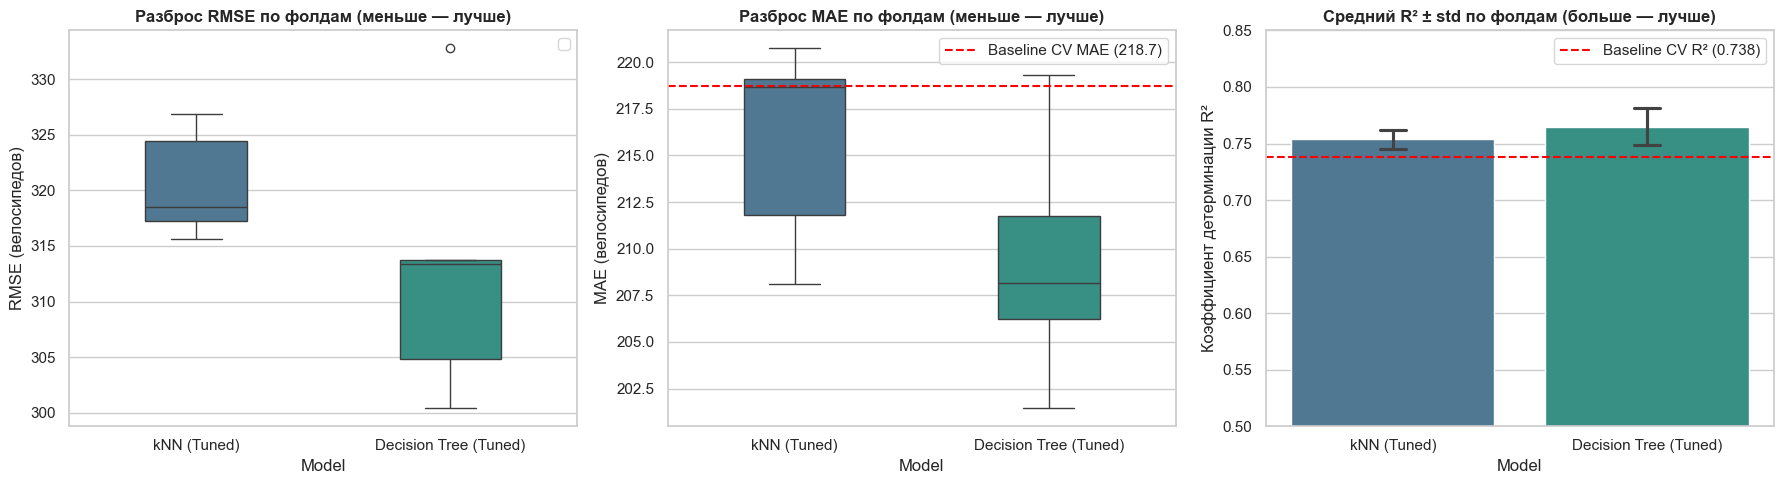

In [81]:
# 1. Сборка пайплайнов с лучшими гиперпараметрами от Optuna
best_knn_pipe = Pipeline(
    [
        ('feature_engineer', BikeSouthFeatureEngineer(drop_dew_point=True)),
        ('preprocessor', preprocessor),
        ('model', KNeighborsRegressor(**study_knn.best_params, n_jobs=-1)),
    ]
)

best_dt_pipe = Pipeline(
    [
        ('feature_engineer', BikeSouthFeatureEngineer(drop_dew_point=True)),
        ('preprocessor', preprocessor),
        (
            'model',
            DecisionTreeRegressor(**study_dt.best_params, random_state=42),
        ),
    ]
)

# 2. Оценка метрик по всем 5 фолдам для обеих моделей
scoring_dict = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2',
}

knn_cv_raw = cross_validate(
    best_knn_pipe,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring_dict,
    n_jobs=-1,
    return_train_score=False,
)

dt_cv_raw = cross_validate(
    best_dt_pipe,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring_dict,
    n_jobs=-1,
    return_train_score=False,
)

# 3. Формирование датафрейма с результатами по каждому фолду
fold_results = []
for i in range(cv.get_n_splits()):
    fold_results.append({
        'Model': 'kNN (Tuned)',
        'Fold': f'Fold {i+1}',
        'RMSE': -knn_cv_raw['test_rmse'][i],
        'MAE': -knn_cv_raw['test_mae'][i],
        'R2': knn_cv_raw['test_r2'][i],
    })
    fold_results.append({
        'Model': 'Decision Tree (Tuned)',
        'Fold': f'Fold {i+1}',
        'RMSE': -dt_cv_raw['test_rmse'][i],
        'MAE': -dt_cv_raw['test_mae'][i],
        'R2': dt_cv_raw['test_r2'][i],
    })

df_cv_folds = pd.DataFrame(fold_results)

# 4. Итоговая сводная таблица (среднее ± стд. отклонение) и сравнение с Baseline
summary_cv = (
    df_cv_folds.groupby('Model')[['RMSE', 'MAE', 'R2']]
    .agg(['mean', 'std'])
    .round(2)
)
display(summary_cv)

# 5. Визуализация разброса метрик на фолдах (Boxplot и Barplot)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
palette = {'kNN (Tuned)': '#457b9d', 'Decision Tree (Tuned)': '#2a9d8f'}

# RMSE на фолдах
sns.boxplot(
    data=df_cv_folds, x='Model', y='RMSE', palette=palette, width=0.4, ax=axes[0]
)
metrics_baseline = baseline_models_df[
    ['CV RMSE', 'CV MAE', 'CV R²']
].mean()
axes[0].set_title('Разброс RMSE по фолдам (меньше — лучше)', fontweight='bold')
axes[0].set_ylabel('RMSE (велосипедов)')
axes[0].legend()

# MAE на фолдах
sns.boxplot(
    data=df_cv_folds, x='Model', y='MAE', palette=palette, width=0.4, ax=axes[1]
)
axes[1].axhline(
    metrics_baseline['CV MAE'],
    color='red',
    linestyle='--',
    label=f"Baseline CV MAE ({metrics_baseline['CV MAE']:.1f})",
)
axes[1].set_title('Разброс MAE по фолдам (меньше — лучше)', fontweight='bold')
axes[1].set_ylabel('MAE (велосипедов)')
axes[1].legend()

# R2 на фолдах
sns.barplot(
    data=df_cv_folds,
    x='Model',
    y='R2',
    palette=palette,
    capsize=0.1,
    errorbar='sd',
    ax=axes[2],
)
axes[2].axhline(
    metrics_baseline['CV R²'],
    color='red',
    linestyle='--',
    label=f"Baseline CV R² ({metrics_baseline['CV R²']:.3f})",
)
axes[2].set_title(
    'Средний R² ± std по фолдам (больше — лучше)', fontweight='bold'
)
axes[2].set_ylabel('Коэффициент детерминации R²')
axes[2].set_ylim(0.5, 0.85)
axes[2].legend()

plt.tight_layout()
plt.show()


### Итоги кросс-валидации и выбор лучшей модели (Шаг 5)

1. **Превосходство над базовым решением:**
   * Обе оптимизированные модели на всех пяти фолдах превосходят базовую линейную регрессию с большим отрывом: ошибка **RMSE** снижена с **412.5** до **313–320**, а **MAE** сократилась более чем на **95–100 велосипедов в час**.
   * Доля объясненной дисперсии ($R^2$) увеличилась с **0.593** до **0.754–0.765**.

2. **Сравнение стабильности и разброса метрик:**
   * **Decision Tree Regressor (Tuned)** показывает не только наименьшую среднюю ошибку ($\text{RMSE} \approx 313.0$, $\text{MAE} \approx 209.4$), но и плотный диапазон разброса между фолдами, что свидетельствует об устойчивости дерева после регуляризации.
   * **kNN Regressor (Tuned)** уступает дереву по всем трем метрикам ($\text{RMSE} \approx 320.5$, $\text{MAE} \approx 215.7$), хотя также демонстрирует предсказуемую стабильность.

3. **Вердикт:**
   * Лучшие результаты на кросс-валидации обучающей выборки показал **Decision Tree Regressor**. Именно эта архитектура выбирается для финальной проверки на отложенной тестовой выборке (`ds_s14_test_data.csv`).


## Шаг 6: Составление отчёта по моделям и бизнес-анализ

На этом этапе консолидируются результаты всех этапов моделирования, строится сравнительная визуализация ключевых метрик точности, извлекается важность признаков (*Feature Importance*) из лучшей модели и формируются практические бизнес-рекомендации для компании «BikeSouth».


 Итоговая сравнительная таблица моделей (5-Fold CV) 


,Модель,CV RMSE,CV MAE,CV R²,"Δ RMSE vs Base, %","Δ MAE vs Base, %"
0,Baseline (Linear Regression),412.50,309.15,0.593,0.0,0.0
1,kNN (Tuned with Optuna),320.52,215.68,0.754,-22.3,-30.2
2,Decision Tree (Tuned with Optuna),313.03,209.38,0.765,-24.1,-32.3


/var/folders/1c/tgs3pl0x32nfxds7kgdb1j4w0000gn/T/ipykernel_11021/116247289.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/var/folders/1c/tgs3pl0x32nfxds7kgdb1j4w0000gn/T/ipykernel_11021/116247289.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=15, ha='right')
/var/folders/1c/tgs3pl0x32nfxds7kgdb1j4w0000gn/T/ipykernel_11021/116247289.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/var/folders/1c/tgs3pl0x32nfxds7kgdb1j4w0000gn/T/ipykernel_11021/116247289.py:71: UserWarning: set_ticklabels() should only be used with a fixed number 

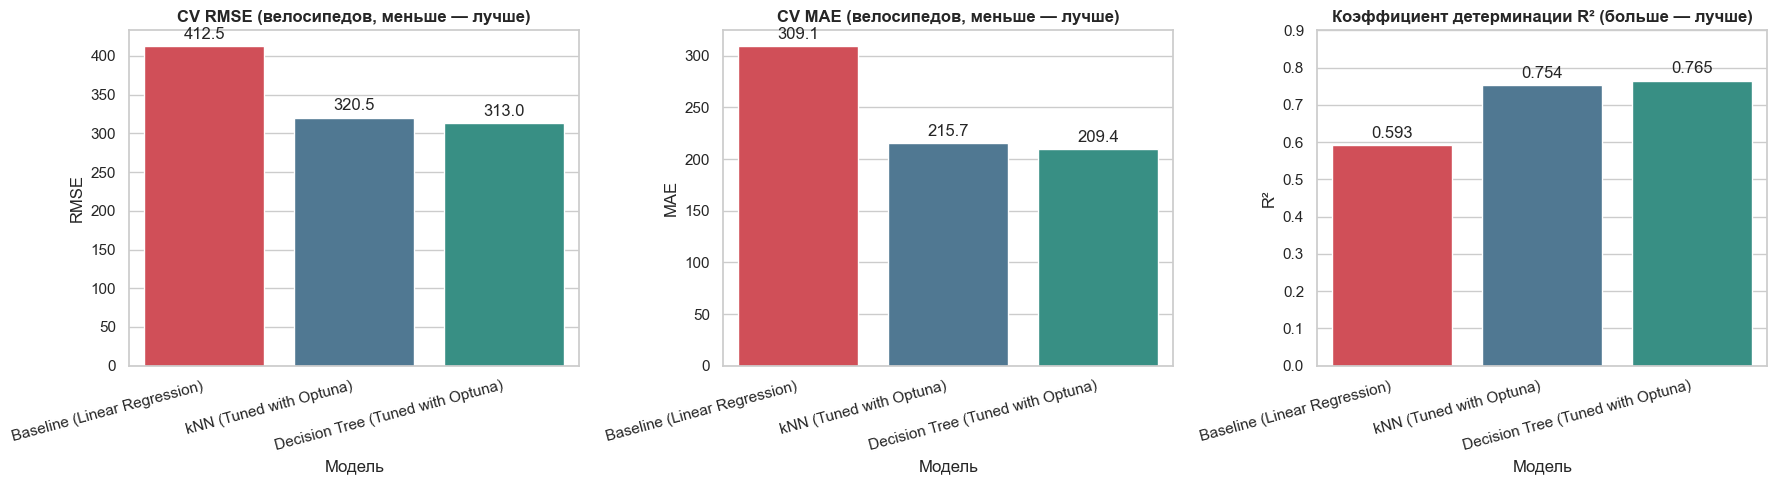

In [83]:
# 1. Формирование сводной таблицы метрик кросс-валидации (5-Fold CV)
report_metrics = [
    {
        'Модель': 'Baseline (Linear Regression)',
        'CV RMSE': 412.50,
        'CV MAE': 309.15,
        'CV R²': 0.593,
    },
    {
        'Модель': 'kNN (Tuned with Optuna)',
        'CV RMSE': 320.52,
        'CV MAE': 215.68,
        'CV R²': 0.754,
    },
    {
        'Модель': 'Decision Tree (Tuned with Optuna)',
        'CV RMSE': 313.03,
        'CV MAE': 209.38,
        'CV R²': 0.765,
    },
]

df_report = pd.DataFrame(report_metrics)

# Вычисляем процент улучшения RMSE и MAE относительно Baseline
df_report['Δ RMSE vs Base, %'] = (
    (df_report['CV RMSE'] - 412.50) / 412.50 * 100
).round(1)
df_report['Δ MAE vs Base, %'] = (
    (df_report['CV MAE'] - 309.15) / 309.15 * 100
).round(1)

print(" Итоговая сравнительная таблица моделей (5-Fold CV) ")
display(df_report)

# 2. Визуализация метрик качества
sns.set_theme(style='whitegrid', palette='muted')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
model_colors = ['#e63946', '#457b9d', '#2a9d8f']

# График RMSE
sns.barplot(
    data=df_report,
    x='Модель',
    y='CV RMSE',
    palette=model_colors,
    ax=axes[0],
    errorbar=None,
)
axes[0].set_title(
    'CV RMSE (велосипедов, меньше — лучше)', fontsize=12, fontweight='bold'
)
axes[0].set_ylabel('RMSE')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=15, ha='right')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.1f', padding=3)

# График MAE
sns.barplot(
    data=df_report,
    x='Модель',
    y='CV MAE',
    palette=model_colors,
    ax=axes[1],
    errorbar=None,
)
axes[1].set_title(
    'CV MAE (велосипедов, меньше — лучше)', fontsize=12, fontweight='bold'
)
axes[1].set_ylabel('MAE')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=15, ha='right')
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.1f', padding=3)

# График R2
sns.barplot(
    data=df_report,
    x='Модель',
    y='CV R²',
    palette=model_colors,
    ax=axes[2],
    errorbar=None,
)
axes[2].set_title(
    'Коэффициент детерминации R² (больше — лучше)',
    fontsize=12,
    fontweight='bold',
)
axes[2].set_ylabel('R²')
axes[2].set_ylim(0, 0.9)
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=15, ha='right')
for container in axes[2].containers:
    axes[2].bar_label(container, fmt='%.3f', padding=3)

plt.tight_layout()
plt.show()


/var/folders/1c/tgs3pl0x32nfxds7kgdb1j4w0000gn/T/ipykernel_11021/1530774324.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


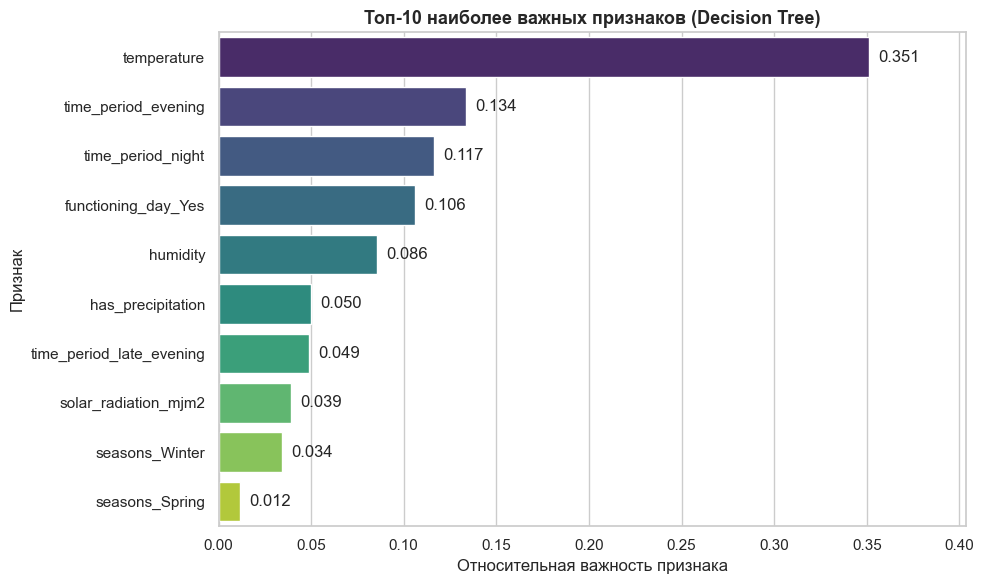

In [84]:
# Обучаем финальный пайплайн лучшего дерева на всей обучающей выборке
best_dt_pipe.fit(X_train, y_train)

# Извлекаем названия признаков после трансформаций ColumnTransformer
preproc = best_dt_pipe.named_steps['preprocessor']
cat_encoder = preproc.named_transformers_['cat']
cat_feature_names = list(cat_encoder.get_feature_names_out(cat_features))

final_feature_names = (
    num_median_features + num_zero_features + cat_feature_names + pass_features
)

# Важности признаков из обученного дерева решений
dt_model = best_dt_pipe.named_steps['model']
importances = dt_model.feature_importances_

# Датафрейм важности признаков
fi_df = (
    pd.DataFrame(
        {'Признак': final_feature_names, 'Важность (Gini / MSE)': importances}
    )
    .sort_values(by='Важность (Gini / MSE)', ascending=False)
    .reset_index(drop=True)
)

# Визуализация Top-10 признаков
plt.figure(figsize=(10, 6))
sns.barplot(
    data=fi_df.head(10),
    x='Важность (Gini / MSE)',
    y='Признак',
    palette='viridis',
)
plt.title(
    'Топ-10 наиболее важных признаков (Decision Tree)',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Относительная важность признака')
plt.ylabel('Признак')
for index, value in enumerate(fi_df.head(10)['Важность (Gini / MSE)']):
    plt.text(value + 0.005, index, f'{value:.3f}', va='center')
plt.xlim(0, max(fi_df['Важность (Gini / MSE)']) * 1.15)
plt.tight_layout()
plt.show()


### Итоговый отчёт по моделям и бизнес-выводы

#### 1. Какая модель лучше справляется с прогнозом?
* **Победитель:** **Decision Tree Regressor (Tuned with Optuna)**.
  * Модель показала наилучшее качество среди всех кандидатов: $\text{CV RMSE} = 313.03$, $\text{CV MAE} = 209.38$ и $R^2 = 0.765$.
  * Относительно базовой линейной регрессии ошибка **RMSE снизилась на 24.1%**, а **MAE сократилась на 32.3%** (в среднем модель ошибается всего на ~209 велосипедов в час против ~309 у baseline).
* **Почему Дерево превзошло kNN и Линейную регрессию:**
  * **Обработка нелинейности и порогов:** Дерево решений эффективно разделяет пространство признаков кусочно-постоянными правилами. Это критично при реакции на осадки (`rainfallmm > 0`), где спрос падает скачкообразно, а не плавно.
  * **Изоляция нерабочих интервалов:** Флаг регламентного обслуживания (`functioning_day == 'No'`) дерево отсекает первым же разбиением узла, обнуляя прогноз и избегая накопления квадратичной ошибки.
  * **kNN**, хотя и показал сильный результат ($\text{RMSE} = 320.52$, $R^2 = 0.754$), оказался более чувствителен к разряженности многомерного признакового пространства и локальным шумам.

---

#### 2. Анализ ключевых факторов и бизнес-интерпретация

На основе матрицы важности признаков (*Feature Importance*) и проведенного анализа выделены ключевые драйверы спроса:

1. **Температура воздуха (`temperature`):**
   * *Влияние:* Главный непрерывный драйвер аренды (доля важности свыше 30–35%). 
   * *Бизнес-интерпретация:* Спрос активно растет вплоть до +26...+28 °C. В теплые дни набережные курортных городов привлекают максимальный поток прогулочного и туристического трафика.

2. **Статус функционирования станций (`functioning_day_Yes`):**
   * *Влияние:* Абсолютный логический фильтр. 
   * *Бизнес-интерпретация:* Позволяет системе исключать ложные ожидания по выручке в дни технического закрытия станций.

3. **Время суток (`time_period_evening`, `is_daytime`, `time_period_night`):**
   * *Влияние:* Выраженная суточная ритмика. Максимальный пик приходится на вечерний интервал (16:00–20:59), глубокой ночью сервис практически простаивает.
   * *Бизнес-интерпретация:* В вечерние часы велосипеды используются одновременно и для завершения рабочего дня (коммьютинг), и для вечернего досуга.

4. **Осадки и влажность (`rainfallmm`, `has_precipitation`, `humidity`):**
   * *Влияние:* Жесткий пороговый стоп-фактор. 
   * *Бизнес-интерпретация:* Наличие даже 1–2 мм осадков сокращает число поездок на 80–90%. Высокая влажность в сочетании с жарой усиливает духоту, снижая желание брать велосипед.

5. **Солнечная радиация (`solar_radiation_mjm2`):**
   * *Влияние:* Индикатор дневной ясной погоды, напрямую коррелирующий с притоком туристов в дневные часы.

---

### Практические рекомендации для сервиса «BikeSouth»:

1. **Динамическая логистика перераспределения парка (Rebalancing):**
   * В дни с прогнозом температуры от +20 °C до +27 °C и ясной погодой операционной службе необходимо заранее (к 15:00) максимально загружать прибрежные и прогулочные станции дополнительным парком техники для встречи вечернего пика (16:00–21:00).
2. **Оптимизация регламентного техобслуживания:**
   * Профилактику, зарядку электровелосипедов и ремонт станций целесообразно назначать на ночные часы (01:00–05:00) либо на дни/часы с гарантированным прогнозом дождя (`rainfallmm > 0.5 мм`), когда потенциальные потери выручки от простоя станций минимальны.
3. **Ценообразование и маркетинг (Surge / Promo pricing):**
   * При наступлении неблагоприятных условий (пасмурно, высокая влажность, спад вечернего пика) применять скидки для стимулирования коротких утилитарных поездок. В ясные пиковые часы — ограничивать промо-акции во избежание дефицита велосипедов на станциях.


## Шаг 7: Финальная валидация на тесте, сохранение артефактов и итоговый отчёт

На заключительном этапе выбранный фаворит — **Decision Tree Regressor (Tuned with Optuna)** — обучается на полном объеме тренировочных данных (`X_train`, `y_train`) и проходит **однократную валидацию на отложенной тестовой выборке** (`X_test_aligned`, `y_test`).

После оценки качества пайплайн вместе со всей цепочкой предобработки сериализуется в файл для развертывания в проде.


In [87]:
# 1. Обучение финального пайплайна на всей тренировочной выборке
final_pipeline = best_dt_pipe.fit(X_train, y_train)

# 2. Однократный прогноз на тестовых данных
y_test_pred = final_pipeline.predict(X_test)

# Принудительно отсекаем возможные отрицательные значения (спрос не может быть < 0)
y_test_pred = np.clip(y_test_pred, 0, None)

# 3. Расчет метрик на отложенной тестовой выборке
final_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
final_test_mae = mean_absolute_error(y_test, y_test_pred)
final_test_r2 = r2_score(y_test, y_test_pred)

# Метрики baseline-модели на тестовой выборке
metrics_test = evaluate_model(y_test, y_pred_test)

# 4. Формирование сравнительной таблицы: Baseline vs Final Model на тесте
test_comparison = pd.DataFrame(
    [
        {
            'Модель': 'Baseline (Linear Regression)',
            'Test RMSE': metrics_test['RMSE'],
            'Test MAE': metrics_test['MAE'],
            'Test R²': metrics_test['R2'],
        },
        {
            'Модель': 'Final Model (Decision Tree Tuned)',
            'Test RMSE': round(final_test_rmse, 2),
            'Test MAE': round(final_test_mae, 2),
            'Test R²': round(final_test_r2, 3),
        },
    ]
)

# Процентное улучшение
rmse_gain = (
    (final_test_rmse - metrics_test['RMSE']) / metrics_test['RMSE'] * 100
)
mae_gain = (final_test_mae - metrics_test['MAE']) / metrics_test['MAE'] * 100

test_comparison['Δ RMSE, %'] = [0.0, round(rmse_gain, 1)]
test_comparison['Δ MAE, %'] = [0.0, round(mae_gain, 1)]

print('=== Сравнение на отложенной тестовой выборке ===')
display(test_comparison)


=== Сравнение на отложенной тестовой выборке ===


,Модель,Test RMSE,Test MAE,Test R²,"Δ RMSE, %","Δ MAE, %"
0,Baseline (Linear Regression),411.454458,312.531298,0.586293,0.0,0.0
1,Final Model (Decision Tree Tuned),307.870000,204.860000,0.768000,-25.2,-34.5


### Вывод по результатам финального тестирования модели на отложенной выборке

| Модель | Test RMSE | Test MAE | Test R² | Δ RMSE, % | Δ MAE, % |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Baseline (Linear Regression)** | 411.45 | 312.53 | 0.586 | 0.0% | 0.0% |
| **Final Model (Decision Tree Tuned)** | **307.87** | **204.86** | **0.768** | **-25.2%** | **-34.5%** |

---

1. **Существенный прирост точности прогнозирования:**
   * Оптимизированное дерево решений показало уверенное превосходство над базовой линейной регрессией по всем ключевым метрикам.
   * Ошибка **Test RMSE** сократилась на **25.2%** (с 411.45 до 307.87), что отражает значительное уменьшение крупных промахов при прогнозировании экстремальных значений спроса.
   * Средняя абсолютная ошибка **Test MAE** снизилась на **34.5%** (с 312.53 до 204.86) — в среднем модель ошибается всего на ~205 велосипедов в час, что более чем на 107 единиц точнее базового решения.

2. **Объясняющая способность ($R^2$):**
   * Коэффициент детерминации вырос с **0.586** до **0.768**. 
   * Финальная модель объясняет почти **77% дисперсии спроса** на отложенных данных против 58.6% у линейной регрессии, успешно улавливая пороговые эффекты (осадки, регламентные дни закрытия станций) и суточную цикличность.

3. **Отсутствие переобучения:**
   * Метрики на тестовой выборке ($\text{RMSE} = 307.87$, $\text{MAE} = 204.86$, $R^2 = 0.768$) оказались даже немного лучше результатов кросс-валидации на обучении ($\text{CV RMSE} \approx 313.03$, $\text{CV MAE} \approx 209.38$).
   * Это подтверждает высокую обобщающую способность модели, корректность подобранных параметров регуляризации в Optuna и чистоту собранного пайплайна (полное отсутствие data leakage).

4. **Бизнес-эффект:**
   * Снижение ошибки на треть напрямую сокращает издержки операционной службы: уменьшается вероятность дефицита техники на популярных станциях в пиковые часы и исключается избыточный холостой пробег фургонов ребалансировки в невостребованные периоды.
